# Validacion del Modelo SV con Datos Sinteticos

**Objetivo:** Verificar que el sampler MCMC recupera correctamente
los parametros de un proceso SV con parametros conocidos.

Este es el primer paso antes de aplicar el modelo a datos reales.

## Procedimiento
1. Generar datos sinteticos con parametros conocidos (mu, phi, sigma_eta)
2. Correr el MCMC sobre los datos sinteticos
3. Verificar que las posteriors cubren los valores verdaderos
4. Diagnosticos de convergencia

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('../..'))

import numpy as np
import matplotlib.pyplot as plt

from tesis.bayesian.sv_model.stochastic_volatility import (
    simulate_sv_data,
    SVPriors,
    SVSamplerConfig,
    SVMetropolisWithinGibbs,
    summary_table,
)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 4)

## 1. Generar Datos Sinteticos

T = 1500 observaciones
Parametros verdaderos: mu=-9.0, phi=0.97, sigma_eta=0.15
y: mean=-0.0002, std=0.0116


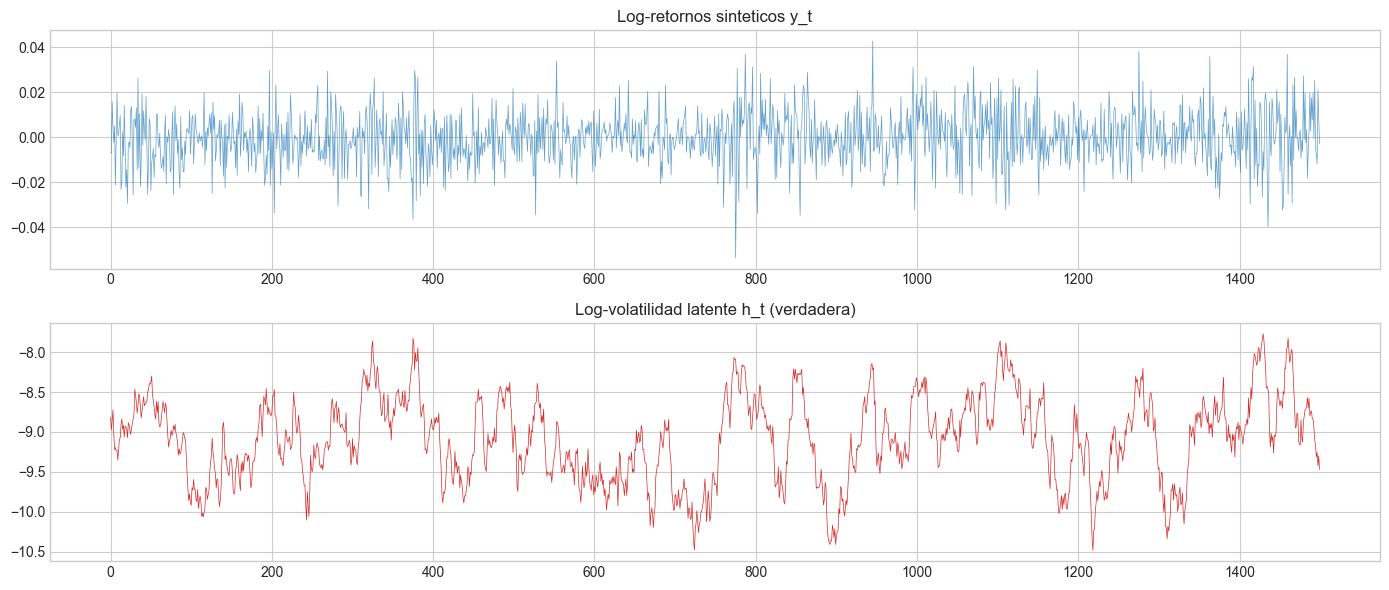

In [2]:
# Parametros verdaderos (tipicos para BTC diario)
TRUE_MU = -9.0
TRUE_PHI = 0.97
TRUE_SIGMA_ETA = 0.15
T = 1500  # ~4 anos de datos diarios

data = simulate_sv_data(T=T, mu=TRUE_MU, phi=TRUE_PHI, sigma_eta=TRUE_SIGMA_ETA, seed=42)
y = data['y']
h_true = data['h']

print(f'T = {T} observaciones')
print(f'Parametros verdaderos: mu={TRUE_MU}, phi={TRUE_PHI}, sigma_eta={TRUE_SIGMA_ETA}')
print(f'y: mean={y.mean():.4f}, std={y.std():.4f}')

fig, axes = plt.subplots(2, 1, figsize=(14, 6))
axes[0].plot(y, linewidth=0.5, alpha=0.7)
axes[0].set_title('Log-retornos sinteticos y_t')
axes[1].plot(h_true, linewidth=0.5, color='#d62828')
axes[1].set_title('Log-volatilidad latente h_t (verdadera)')
plt.tight_layout()
plt.show()

## 2. Correr MCMC

In [3]:
priors = SVPriors(
    mu_0=-9.0, sigma_mu=3.0,
    a_phi=20.0, b_phi=1.5,
    a_sigma=2.5, b_sigma=0.025,
)

config = SVSamplerConfig(
    n_iter=8_000,
    burn_in=2_000,
    thin=1,
    adapt=True,
)

sampler = SVMetropolisWithinGibbs(y, priors=priors, config=config)
result = sampler.run(verbose=True)

  iter 1000/10000 (burn-in) | mu=-9.210 phi=0.9526 sigma_eta=0.1978


  iter 2000/10000 (burn-in) | mu=-9.225 phi=0.9511 sigma_eta=0.1954


  iter 3000/10000 (sampling) | mu=-8.806 phi=0.9691 sigma_eta=0.1709


  iter 4000/10000 (sampling) | mu=-9.090 phi=0.9804 sigma_eta=0.1278


  iter 5000/10000 (sampling) | mu=-9.113 phi=0.9312 sigma_eta=0.2026


  iter 6000/10000 (sampling) | mu=-8.899 phi=0.9580 sigma_eta=0.1309


  iter 7000/10000 (sampling) | mu=-8.910 phi=0.9712 sigma_eta=0.1175


  iter 8000/10000 (sampling) | mu=-9.026 phi=0.9495 sigma_eta=0.1883


  iter 9000/10000 (sampling) | mu=-9.129 phi=0.9505 sigma_eta=0.1961


  iter 10000/10000 (sampling) | mu=-9.162 phi=0.9410 sigma_eta=0.1916

MCMC completado: 8000 muestras posteriores.
  mu:        mean=-9.0475, std=0.1092
  phi:       mean=0.9567, std=0.0125
  sigma_eta: mean=0.1638, std=0.0260


## 3. Diagnosticos de Convergencia

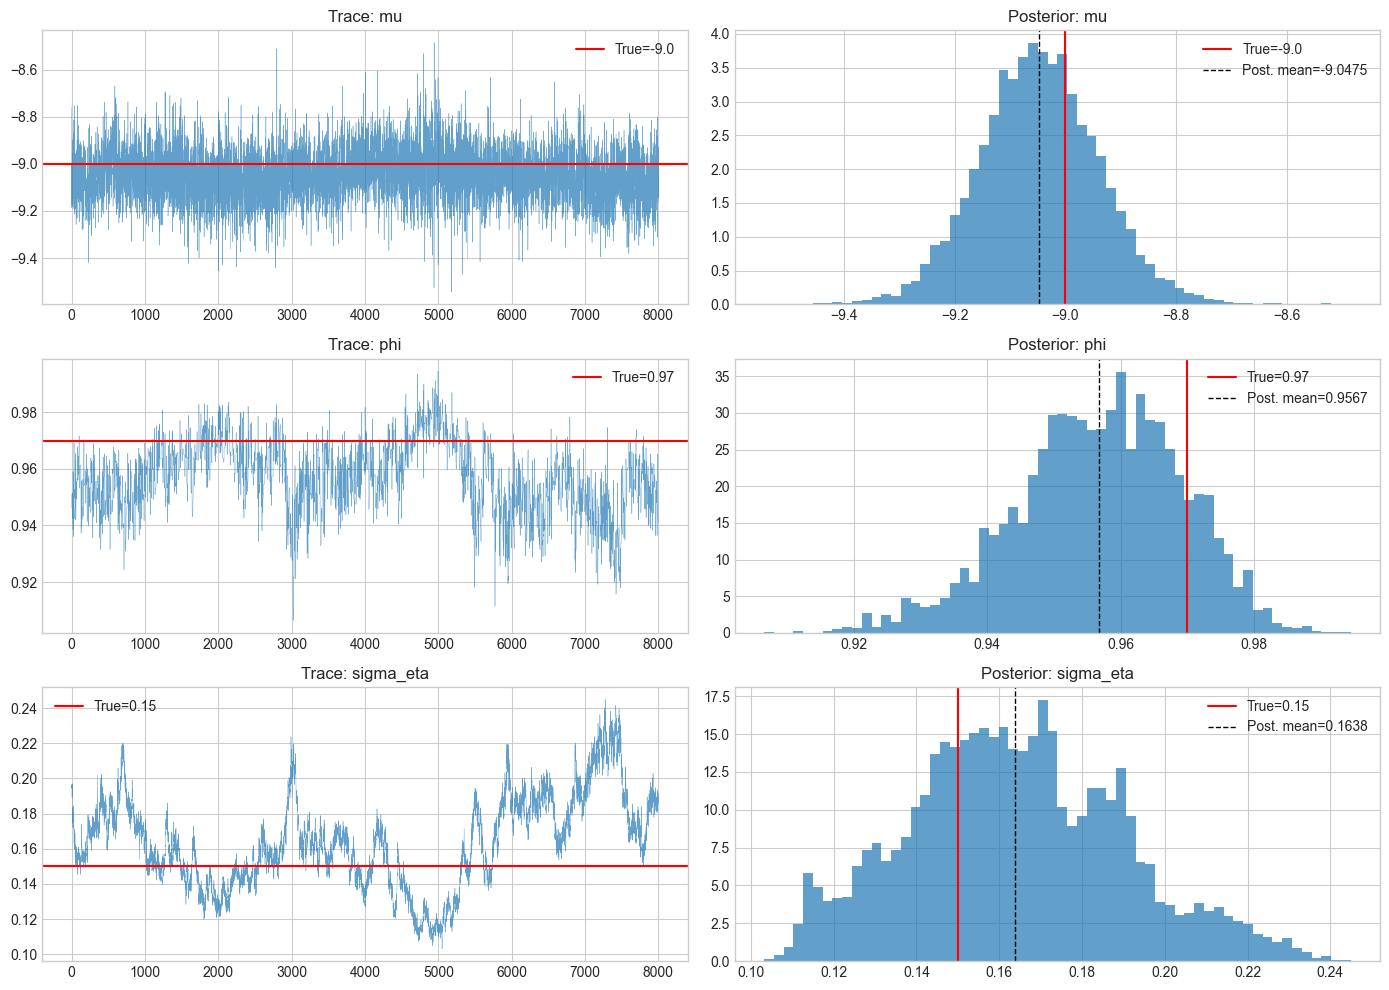

In [4]:
# Trace plots
fig, axes = plt.subplots(3, 2, figsize=(14, 10))

params_data = [
    ('mu', result['mu'], TRUE_MU),
    ('phi', result['phi'], TRUE_PHI),
    ('sigma_eta', result['sigma_eta'], TRUE_SIGMA_ETA),
]

for i, (name, chain, true_val) in enumerate(params_data):
    # Trace
    axes[i, 0].plot(chain, linewidth=0.3, alpha=0.7)
    axes[i, 0].axhline(true_val, color='r', linewidth=1.5, label=f'True={true_val}')
    axes[i, 0].set_title(f'Trace: {name}')
    axes[i, 0].legend()
    
    # Histogram
    axes[i, 1].hist(chain, bins=60, density=True, alpha=0.7)
    axes[i, 1].axvline(true_val, color='r', linewidth=1.5, label=f'True={true_val}')
    axes[i, 1].axvline(np.mean(chain), color='k', linewidth=1, linestyle='--', label=f'Post. mean={np.mean(chain):.4f}')
    axes[i, 1].set_title(f'Posterior: {name}')
    axes[i, 1].legend()

plt.tight_layout()
plt.show()

In [5]:
# Tabla resumen de diagnosticos
diag = summary_table(result)

print(f'{"Param":<12} {"Mean":>10} {"Std":>10} {"Q2.5%":>10} {"Q97.5%":>10} {"ESS":>8}')
print('-' * 62)
for param, d in diag.items():
    print(f'{param:<12} {d["mean"]:>10.4f} {d["std"]:>10.4f} {d["q025"]:>10.4f} {d["q975"]:>10.4f} {d["ess"]:>8.1f}')

print(f'\nValores verdaderos: mu={TRUE_MU}, phi={TRUE_PHI}, sigma_eta={TRUE_SIGMA_ETA}')
print('Verificar que los valores verdaderos caen dentro de los intervalos de credibilidad al 95%.')

Param              Mean        Std      Q2.5%     Q97.5%      ESS
--------------------------------------------------------------
mu              -9.0475     0.1092    -9.2588    -8.8292    586.9
phi              0.9567     0.0125     0.9293     0.9789     21.7
sigma_eta        0.1638     0.0260     0.1153     0.2191     12.1
h[0]            -9.0148     0.4009    -9.8535    -8.2408     41.3
h[375]          -8.1083     0.2612    -8.6436    -7.6153     34.0
h[750]          -9.3213     0.3187    -9.9111    -8.6859     33.5
h[1125]         -8.6951     0.3392    -9.3285    -8.0101     25.1
h[1499]         -8.8128     0.3452    -9.4924    -8.1542     84.1

Valores verdaderos: mu=-9.0, phi=0.97, sigma_eta=0.15
Verificar que los valores verdaderos caen dentro de los intervalos de credibilidad al 95%.


## 4. Comparacion: h estimada vs h verdadera

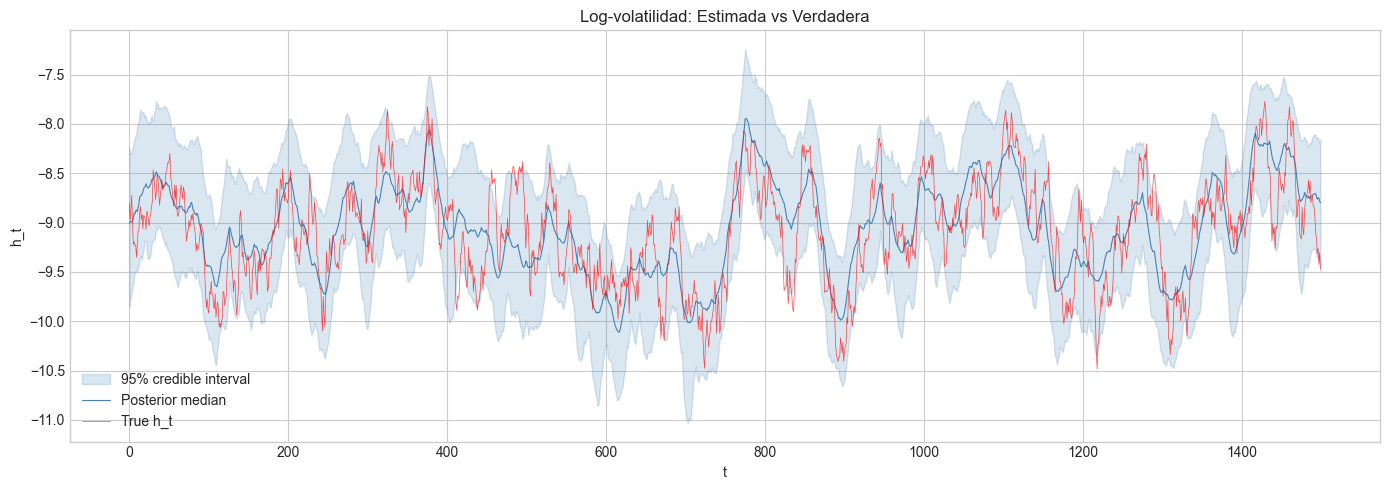

Coverage del intervalo 95%: 95.00% (ideal: ~95%)


In [6]:
# Posterior median y bandas para h_t
h_samples = result['h']  # (n_samples, T)
h_median = np.median(h_samples, axis=0)
h_q025 = np.percentile(h_samples, 2.5, axis=0)
h_q975 = np.percentile(h_samples, 97.5, axis=0)

fig, ax = plt.subplots(figsize=(14, 5))
t_axis = np.arange(T)

ax.fill_between(t_axis, h_q025, h_q975, alpha=0.2, color='steelblue', label='95% credible interval')
ax.plot(t_axis, h_median, color='steelblue', linewidth=0.8, label='Posterior median')
ax.plot(t_axis, h_true, color='red', linewidth=0.5, alpha=0.7, label='True h_t')

ax.set_title('Log-volatilidad: Estimada vs Verdadera')
ax.set_xlabel('t')
ax.set_ylabel('h_t')
ax.legend()
plt.tight_layout()
plt.show()

# Coverage: que fraccion de h_t verdaderos caen en el intervalo
coverage = np.mean((h_true >= h_q025) & (h_true <= h_q975))
print(f'Coverage del intervalo 95%: {coverage:.2%} (ideal: ~95%)')

## 5. Siguiente Paso

Si los parametros se recuperan correctamente y los diagnosticos son buenos:
- **Pasar a datos reales de BTC** en el notebook `03_sv_btc_real.ipynb`
- Usar log-retornos diarios de BTC como `y`
- Estimar (mu, phi, sigma_eta) y la serie de h_t
- Generar trayectorias futuras con la posterior